In [1]:
import pyro
import torch

import matplotlib.pyplot as plt

from mmbo.nn import RegBNN, RegBNNGuide, LayeredRegBNN, LayeredRegBNNGuide, posterior_samples
from mmbo.examples.demo import paciorek_demo
from mmbo.training import do_svi

#device = "cuda:3"

## Get training data

In [2]:
X_train_main = paciorek_demo['X_train_main']
X_train_mm = paciorek_demo['X_train_mm']
X_test = paciorek_demo['X_test']
Y_train_main = paciorek_demo['Y_train_main']
Y_train_mm = paciorek_demo['Y_train_mm']
Y_test_main = paciorek_demo['Y_test_main']
Y_test_mm = paciorek_demo['Y_test_mm']

## Train uni-modal model

In [3]:
model = RegBNN.from_data(X_train = X_train_main, Y_train = Y_train_main, hidden_widths=[256,256])
guide = RegBNNGuide(model)

#model = model.to(device)
#guide = guide.to(device)

In [4]:
adam = pyro.optim.Adam({"lr": 0.001})
elbo = pyro.infer.Trace_ELBO(num_particles = 1)

svi = pyro.infer.SVI(model, guide, adam, elbo)
params, losses = do_svi(svi, params = None)

2025-09-08 20:54:42 - Start


/home/itaylor/projects/mmbo/.venv/lib64/python3.9/site-packages/torch/distributions/wishart.py:275: UserWarning: Singular sample detected.
  warnings.warn("Singular sample detected.")


2025-09-08 20:55:14 - Step 1000, Elbo loss: 48191.5 +/- 29478.4 (slope = -50573.369 +/- 432.445 loss/k-iter, p-value = 0.000) + 
2025-09-08 20:55:45 - Step 2000, Elbo loss: 16443.8 +/- 10127.8 (slope = -17356.080 +/- 157.310 loss/k-iter, p-value = 0.000) + 
2025-09-08 20:56:18 - Step 3000, Elbo loss: 5727.2 +/- 3351.3 (slope = -5739.887 +/- 53.481 loss/k-iter, p-value = 0.000) + 
2025-09-08 20:56:51 - Step 4000, Elbo loss: 2186.5 +/- 1119.3 (slope = -1913.373 +/- 19.409 loss/k-iter, p-value = 0.000) + 
2025-09-08 20:57:24 - Step 5000, Elbo loss: 1002.4 +/- 378.7 (slope = -645.177 +/- 7.397 loss/k-iter, p-value = 0.000) + 
2025-09-08 20:57:57 - Step 6000, Elbo loss: 603.4 +/- 127.0 (slope = -210.978 +/- 3.916 loss/k-iter, p-value = 0.000) + 
2025-09-08 20:58:29 - Step 7000, Elbo loss: 471.2 +/- 49.1 (slope = -72.601 +/- 2.807 loss/k-iter, p-value = 0.000) + 
2025-09-08 20:59:02 - Step 8000, Elbo loss: 423.1 +/- 28.9 (slope = -29.758 +/- 2.550 loss/k-iter, p-value = 0.000) + 
2025-09-08 

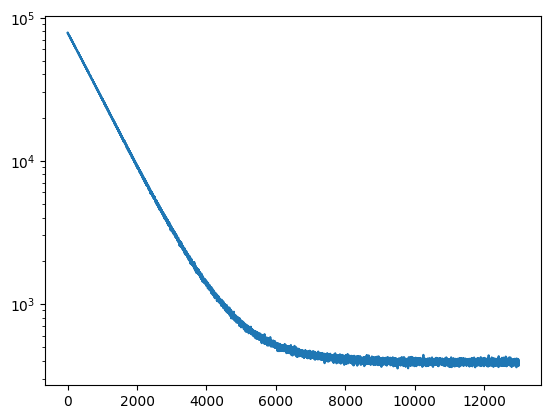

In [6]:
plt.plot(losses)
plt.yscale("log")

In [7]:
samples = posterior_samples(guide, params, 1000)

## Optimize expected improvement

In [22]:
from mmbo.optim import expected_improvement, lcb, probability_improvement, probability_improvement_sigmoid, expected_improvement_softplus

In [20]:
n_swarm = 100

n_iter = 100

low_lim = 0.3
high_lim = 1.0

X_init = torch.rand((n_swarm, 4)) * (high_lim - low_lim) + low_lim

In [24]:


X_opt = X_init.clone()
X_opt.requires_grad_(True)

optim = torch.optim.Adam([X_opt], lr=0.01)

max_ei = [None]*n_iter
for iter in range(n_iter):
    optim.zero_grad()
    ei = expected_improvement_softplus(model, samples, X_opt, Y_train_main.min())
    gain = -ei
    max_ei[iter] = ei.max().detach().item()
    gain.sum().backward()
    optim.step()
    with torch.no_grad():
        X_opt.clamp_(min=low_lim, max=high_lim)
    print(f"{iter}: {max_ei[iter]}")


0: 1.2162501811981201
1: 1.2771730422973633
2: 1.3378500938415527
3: 1.3741083145141602
4: 1.4009994268417358
5: 1.4133070707321167
6: 1.423883318901062
7: 1.4333051443099976
8: 1.4411643743515015
9: 1.447259545326233
10: 1.4566385746002197
11: 1.4583584070205688
12: 1.4596798419952393
13: 1.460436224937439
14: 1.4608354568481445
15: 1.4605876207351685
16: 1.4598489999771118
17: 1.4590407609939575
18: 1.458418369293213
19: 1.4581645727157593
20: 1.4583464860916138
21: 1.4592597484588623
22: 1.466759204864502
23: 1.4726214408874512
24: 1.4773457050323486
25: 1.480505347251892
26: 1.482426404953003
27: 1.483519434928894
28: 1.4837419986724854
29: 1.4833674430847168
30: 1.4824522733688354
31: 1.4813624620437622
32: 1.4802298545837402
33: 1.480352759361267
34: 1.4821131229400635
35: 1.483245611190796
36: 1.4837170839309692
37: 1.4837098121643066
38: 1.4835753440856934
39: 1.4837462902069092
40: 1.483669400215149
41: 1.4832803010940552
42: 1.4827581644058228
43: 1.4821921586990356
44: 1.481

(array([65.,  9.,  0.,  0.,  0.,  0.,  0.,  0.,  0., 26.]),
 array([0.64314604, 0.72720551, 0.81126499, 0.89532453, 0.97938401,
        1.06344342, 1.14750302, 1.2315625 , 1.31562197, 1.39968145,
        1.48374093]),
 <BarContainer object of 10 artists>)

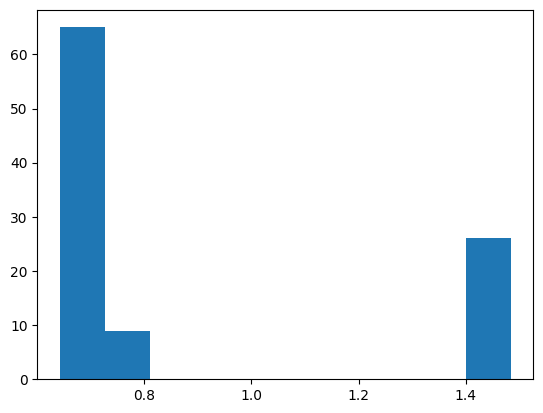

In [ ]:
ei = expected_improvement_softplus(model, samples, X_opt, Y_train_main.min())
plt.hist(ei.detach())

tensor(-0.9998)

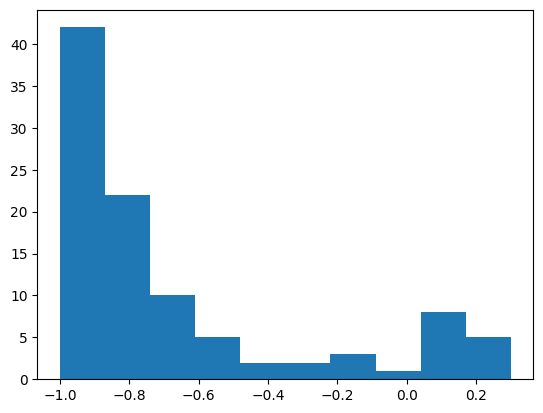

In [31]:
from mmbo.examples.testfunc import paciorek_hf

realized_values = paciorek_hf(X_opt)

plt.hist(realized_values.detach())

Y_train_main.min()

## Train multi-modal layered model

In [32]:
model_layered = LayeredRegBNN.from_data(X_train_main = X_train_main, Y_train_main = Y_train_main, X_train_aux = X_train_mm, Y_train_aux = Y_train_mm, hidden_widths=[256,256])
guide_layered = LayeredRegBNNGuide(model_layered)

In [33]:
adam_layered = pyro.optim.Adam({"lr": 0.001})
elbo_layered = pyro.infer.Trace_ELBO(num_particles = 1)

svi_layered = pyro.infer.SVI(model_layered, guide_layered, adam_layered, elbo_layered)
params_layered, losses_layered = do_svi(svi_layered, params = None)

2025-09-08 22:42:22 - Start


/home/itaylor/projects/mmbo/.venv/lib64/python3.9/site-packages/torch/distributions/wishart.py:275: UserWarning: Singular sample detected.
  warnings.warn("Singular sample detected.")


2025-09-08 22:43:34 - Step 1000, Elbo loss: 45823.9 +/- 29615.7 (slope = -50834.486 +/- 422.333 loss/k-iter, p-value = 0.000) + 
2025-09-08 22:44:41 - Step 2000, Elbo loss: 13583.8 +/- 10415.1 (slope = -17855.962 +/- 158.425 loss/k-iter, p-value = 0.000) + 
2025-09-08 22:45:46 - Step 3000, Elbo loss: 2440.7 +/- 3560.3 (slope = -6099.013 +/- 56.345 loss/k-iter, p-value = 0.000) + 
2025-09-08 22:46:55 - Step 4000, Elbo loss: -1360.8 +/- 1220.2 (slope = -2084.347 +/- 21.686 loss/k-iter, p-value = 0.000) + 
2025-09-08 22:48:01 - Step 5000, Elbo loss: -2675.5 +/- 434.9 (slope = -731.678 +/- 11.219 loss/k-iter, p-value = 0.000) + 
2025-09-08 22:49:09 - Step 6000, Elbo loss: -3148.2 +/- 176.6 (slope = -271.982 +/- 8.830 loss/k-iter, p-value = 0.000) + 
2025-09-08 22:50:14 - Step 7000, Elbo loss: -3329.3 +/- 104.2 (slope = -118.724 +/- 8.598 loss/k-iter, p-value = 0.000) + 
2025-09-08 22:51:18 - Step 8000, Elbo loss: -3409.0 +/- 82.3 (slope = -49.749 +/- 8.448 loss/k-iter, p-value = 0.000) + 


In [34]:
samples_layered = posterior_samples(guide_layered, params_layered, 1000)

/home/itaylor/projects/mmbo/.venv/lib64/python3.9/site-packages/torch/distributions/wishart.py:275: UserWarning: Singular sample detected.
  warnings.warn("Singular sample detected.")


In [35]:
X_opt_layered = X_init.clone()
X_opt_layered.requires_grad_(True)

optim_layered = torch.optim.Adam([X_opt_layered], lr=0.01)

max_ei_layered = [None]*n_iter
for iter in range(n_iter):
    optim_layered.zero_grad()
    ei = expected_improvement_softplus(model_layered, samples_layered, X_opt_layered, Y_train_main.min())
    gain = -ei
    max_ei_layered[iter] = ei.max().detach().item()
    gain.sum().backward()
    optim_layered.step()
    with torch.no_grad():
        X_opt_layered.clamp_(min=low_lim, max=high_lim)
    print(f"{iter}: {max_ei_layered[iter]}")

0: 0.6921039819717407
1: 0.6965939998626709
2: 0.6998986601829529
3: 0.7018296122550964
4: 0.7041942477226257
5: 0.706670343875885
6: 0.7083608508110046
7: 0.7100831270217896
8: 0.7115127444267273
9: 0.7126662731170654
10: 0.7138474583625793
11: 0.7147989273071289
12: 0.7157171368598938
13: 0.716528058052063
14: 0.717222273349762
15: 0.7176892757415771
16: 0.7181125283241272
17: 0.718537449836731
18: 0.7187924981117249
19: 0.7189702391624451
20: 0.7191214561462402
21: 0.7192884683609009
22: 0.7193257212638855
23: 0.7193644642829895
24: 0.7194051742553711
25: 0.7194385528564453
26: 0.7194627523422241
27: 0.7194543480873108
28: 0.7194494605064392
29: 0.7194446921348572
30: 0.7194336652755737
31: 0.7194833755493164
32: 0.7194509506225586
33: 0.7193864583969116
34: 0.7193665504455566
35: 0.7193613052368164
36: 0.7193688154220581
37: 0.7193823456764221
38: 0.7193962335586548
39: 0.7194074988365173
40: 0.7194674015045166
41: 0.7195094227790833
42: 0.7195680141448975
43: 0.719603419303894
44: